# 공부 자료
# https://github.com/HongLabInc/HongLabLLM

In [ ]:
#colab에서 데이터셋을 계속 사용하기위해 구글 드라이브연결
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 훈련 데이터 불러오기 & 구글 드라이브에 저장하기

## kaggle 에서 dataset 다운 받기


In [ ]:
import os
from google.colab import userdata

key = userdata.get('easywoo')

In [ ]:
!pip install kaggle

### 해리포터 다운로드

In [ ]:
!kaggle datasets download -d rupanshukapoor/harry-potter-books

Dataset URL: https://www.kaggle.com/datasets/rupanshukapoor/harry-potter-books
License(s): MIT
100% 2.43M/2.43M [00:00<00:00, 34.9MB/s]



### 엘리스 다운로드

In [ ]:
!kaggle datasets download -d leelatte/alicetxt

Dataset URL: https://www.kaggle.com/datasets/leelatte/alicetxt
License(s): unknown
100% 54.0k/54.0k [00:00<00:00, 45.4MB/s]



## 구글 드라이브에 dataset zip 압축 풀기

In [ ]:
#colab에서 데이터셋을 계속 사용하기위해 구글 드라이브연결
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import zipfile

# project_path = '/content/drive/MyDrive/LLMSearch/DataSet/HarryPotter'
project_path = '/content/drive/MyDrive/LLMSearch/DataSet/alice'

if not os.path.exists(project_path):
  os.makedirs(project_path)
  print('폴더 생성')
with zipfile.ZipFile('alicetxt.zip','r') as zip_ref:
  zip_ref.extractall(project_path)

print('완료')


FileNotFoundError: [Errno 2] No such file or directory: 'alicetxt.zip'

## 파일 내용 확인하기

In [ ]:
import os
# 1.폴더 경로
# folder_path = '/content/drive/MyDrive/LLMSearch/DataSet/HarryPotter/hp_books1-7/hp_books'
folder_path = '/content/drive/MyDrive/LLMSearch/DataSet/alice'

# 2. 경로와 파일 이름 결합
# file_name = 'Book1.txt'
file_name = 'alice.txt'

full_path = os.path.join(folder_path, file_name)

# 3. 파일 불러오기
with open(full_path, 'r', encoding='utf-8') as file:
    content = file.read()
    print(content)


﻿Project Gutenberg's Alice's Adventures in Wonderland, by Lewis Carroll

This eBook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever.  You may copy it, give it away or
re-use it under the terms of the Project Gutenberg License included
with this eBook or online at www.gutenberg.org


Title: Alice's Adventures in Wonderland

Author: Lewis Carroll

Posting Date: June 25, 2008 [EBook #11]
Release Date: March, 1994
[Last updated: December 20, 2011]

Language: English


*** START OF THIS PROJECT GUTENBERG EBOOK ALICE'S ADVENTURES IN WONDERLAND ***










ALICE'S ADVENTURES IN WONDERLAND

Lewis Carroll

THE MILLENNIUM FULCRUM EDITION 3.0




CHAPTER I. Down the Rabbit-Hole

Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do: once or twice she had peeped into the
book her sister was reading, but it had no pictures or conversations in
it, 'and what is the use of a book,' thought Alice 'without pictur

# 전처리(PreProcessing)

## 줄바꿈 처리

In [ ]:
import re # 패턴 찾는 라이브러리
import os # 파일경로 + cleaned_ + 파일 이름을 위해서
def clean_text(dir_name, file_name):
  with open(dir_name+'/'+file_name, 'r',encoding ='utf-8') as file:
    book_text = file.read()

  cleaned_text = re.sub(r'\n+',' ', book_text)
  cleaned_text = re.sub(r'\s+',' ',cleaned_text)

  print("cleaned_" +file_name, len(cleaned_text), "characters")

  with open(dir_name + '/' + "cleaned_"+ file_name,'w',encoding='utf-8') as file:
    file.write(cleaned_text)

path = "/content/drive/MyDrive/LLMSearch/DataSet/alice/alice.txt"
dir_name,file_name = os.path.split(path)

filenames_list = ["/content/drive/MyDrive/LLMSearch/DataSet/alice/alice.txt"]
# #filenames_list = ["alice.txt"]

for filename in filenames_list:
  clean_text(dir_name,file_name)


cleaned_alice.txt 143225 characters


### **줄바꿈** 제거한 결과 확인하기

In [ ]:
import os

folder_path = '/content/drive/MyDrive/LLMSearch/DataSet/alice'

# 2. 경로와 파일 이름 결합

file_name = 'cleaned_alice.txt'

full_path = os.path.join(folder_path, file_name)

# 3. 파일 불러오기
with open(full_path, 'r', encoding='utf-8') as file:
    content = file.read()
    print(content)

﻿Project Gutenberg's Alice's Adventures in Wonderland, by Lewis Carroll This eBook is for the use of anyone anywhere at no cost and with almost no restrictions whatsoever. You may copy it, give it away or re-use it under the terms of the Project Gutenberg License included with this eBook or online at www.gutenberg.org Title: Alice's Adventures in Wonderland Author: Lewis Carroll Posting Date: June 25, 2008 [EBook #11] Release Date: March, 1994 [Last updated: December 20, 2011] Language: English *** START OF THIS PROJECT GUTENBERG EBOOK ALICE'S ADVENTURES IN WONDERLAND *** ALICE'S ADVENTURES IN WONDERLAND Lewis Carroll THE MILLENNIUM FULCRUM EDITION 3.0 CHAPTER I. Down the Rabbit-Hole Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, 'and what is the use of a book,' thought Alice 'without pictures or conversation?' So sh

## 토큰화(Tokenization)

In [ ]:
# 라이브러리 호출
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

문자열 토큰화 해보기

In [ ]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")
text = "Project Gutenberg's Alice's Adventures in Wonderland," # 문자열
tokens = tokenizer.encode(text)

print("글자수:", len(text), "토큰수:",len(tokens))
print(tokens)
print(tokenizer.decode(tokens))
for t in tokens:
  print(f"{t} -> {tokenizer.decode([t])}")

글자수: 53 토큰수: 9
[16775, 20336, 338, 14862, 338, 15640, 287, 42713, 11]
Project Gutenberg's Alice's Adventures in Wonderland,
16775 -> Project
20336 ->  Gutenberg
338 -> 's
14862 ->  Alice
338 -> 's
15640 ->  Adventures
287 ->  in
42713 ->  Wonderland
11 -> ,


## 데이터로더(DataLoader)

In [ ]:
import tiktoken
import torch
from torch.utils.data import Dataset, DataLoader

tokenizer = tiktoken.get_encoding("gpt2")
class MyDataset(Dataset):
  def __init__(self, txt, max_length,stride):
    self.input_ids = []
    self.target_ids = []

    token_ids = tokenizer.encode(txt) # 책 전체를 토큰으로 만듬
    print(token_ids)

    print("# of tokens in txt: ", len(token_ids))

    for i in range(0,len(token_ids)-max_length,stride):
      # 코드 해석을 위한 예시 문장 : Project Gutenberg's Alice's Adventures in Wonderland,
      # 토큰화 된 문장 : [16775, 20336, 338, 14862, 338, 15640, 287, 42713, 11]

      # range(0,len(token_ids)-max_length,stride)
      # len(token_ids) = 9 , max_length = 5 , stride = 2 일때 -> range(0,9-5,2) -> range(0,4,2)
      # 9-5 = 4, range(0,4,2) -> 0~(4-1) -> 0~3 -> step 이 2 니까 , 두번째 실행 시 i = 2 아직 3 이하이므로 진행 -> 세번째 실행시 i = 4이므로 종료->  2번?

      # 첫번째
      # input_chunk = [0:0+5] -> [16775, 20336, 338, 14862, 338]
      # target_chunk = [0+1: 0+5+1] -> [20336, 338, 14862, 338, 15640]

      # 두번째
      # input_chunk = [2: 2+5] -> [338, 14862, 338, 15640, 287]
      # target_chunk = [2+1: 2+ 5 +1] -> [14862, 338, 15640, 287, 42713]

      input_chunk = token_ids[i:i + max_length] # i ~  i + max_length 까지 인덱싱
      target_chunk = token_ids[i+1:i+max_length +1] # i + 1 ~  i + max_length + 1 까지 인덱싱
      self.input_ids.append(torch.tensor(input_chunk)) # type(list) -> type(tensor) 자료형 변환 후 리스트에 추가
      self.target_ids.append(torch.tensor(target_chunk))


    # print(target_chunk)
    # print(tokenizer.decode(target_chunk))
    # print(self.input_ids[:10])
    # print(self.target_ids[:10])


  def __len__(self):
    return len(self.input_ids)

  def __getitem__(self,idx):
    return self.input_ids[idx],self.target_ids[idx]

# with open("/content/drive/MyDrive/LLMSearch/DataSet/alice/alice.txt",'r', encoding = 'utf-8-sig') as file:
#   txt =file.read()
with open("/content/drive/MyDrive/LLMSearch/DataSet/alice/cleaned_alice.txt",'r', encoding = 'utf-8-sig') as file:
  txt =file.read()

dataset = MyDataset(txt,max_length= 32,stride =4) # dataset = [input_ids, target_ids]
print(type(dataset))
train_loader = DataLoader(dataset, batch_size=128, shuffle = True, drop_last= True)


[16775, 20336, 338, 14862, 338, 15640, 287, 42713, 11, 416, 10174, 21298, 770, 46566, 318, 329, 262, 779, 286, 2687, 6609, 379, 645, 1575, 290, 351, 2048, 645, 8733, 16014, 13, 921, 743, 4866, 340, 11, 1577, 340, 1497, 393, 302, 12, 1904, 340, 739, 262, 2846, 286, 262, 4935, 20336, 13789, 3017, 351, 428, 46566, 393, 2691, 379, 7324, 13, 70, 19028, 13, 2398, 11851, 25, 14862, 338, 15640, 287, 42713, 6434, 25, 10174, 21298, 2947, 278, 7536, 25, 2795, 1679, 11, 3648, 685, 36, 10482, 1303, 1157, 60, 13868, 7536, 25, 2805, 11, 9162, 685, 5956, 6153, 25, 3426, 1160, 11, 2813, 60, 15417, 25, 3594, 17202, 33303, 3963, 12680, 21965, 23680, 402, 3843, 1677, 13246, 38, 412, 39453, 8355, 8476, 6, 50, 43685, 3525, 29514, 3268, 370, 1340, 14418, 28182, 17202, 8355, 8476, 6, 50, 43685, 3525, 29514, 3268, 370, 1340, 14418, 28182, 10174, 21298, 3336, 49775, 1677, 22125, 5883, 376, 52, 5639, 49, 5883, 39219, 513, 13, 15, 5870, 29485, 314, 13, 5588, 262, 25498, 12, 39, 2305, 14862, 373, 3726, 284, 651, 8

In [ ]:
import tiktoken
dataiter = iter(train_loader)

x,y = next(dataiter)

print(tokenizer.decode(x[0].tolist()))
print(tokenizer.decode(y[0].tolist()))

 these changes are! I'm never sure what I'm going to be, from one minute to another! However, I've got back to my right size:
 changes are! I'm never sure what I'm going to be, from one minute to another! However, I've got back to my right size: the


## 뉴럴 네트워크 모델 정의

In [ ]:
# 모델 정의 할때 사용하는 상수들
VOCAB_SIZE = tokenizer.n_vocab
# print(VOCAB_SIZE)
CONTEXT_LENGTH = 128
EMB_DIM = 768
NUM_HEADS = 12
NUM_LAYERS = 12
DROP_RATE = 0.1
QKV_BIAS = False

In [ ]:
import torch.nn as nn

class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()

        assert d_out % NUM_HEADS == 0, "d_out must be divisible by n_heads"

        self.d_out = d_out
        self.head_dim = d_out // NUM_HEADS

        self.W_query = nn.Linear(d_in, d_out, bias=QKV_BIAS)
        self.W_key = nn.Linear(d_in, d_out, bias=QKV_BIAS)
        self.W_value = nn.Linear(d_in, d_out, bias=QKV_BIAS)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(DROP_RATE)
        self.register_buffer('mask', torch.triu(torch.ones(CONTEXT_LENGTH, CONTEXT_LENGTH), diagonal=1))

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x)  # (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        keys = keys.view(b, num_tokens, NUM_HEADS, self.head_dim)
        values = values.view(b, num_tokens, NUM_HEADS, self.head_dim)
        queries = queries.view(b, num_tokens, NUM_HEADS, self.head_dim)

        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        attn_scores = queries @ keys.transpose(2, 3)

        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vec = (attn_weights @ values).transpose(1, 2)

        context_vec = context_vec.reshape(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)

        return context_vec

class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))

class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(EMB_DIM, 4 * EMB_DIM),
            GELU(),
            nn.Linear(4 * EMB_DIM, EMB_DIM),
        )

    def forward(self, x):
        return self.layers(x)

class TransformerBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=EMB_DIM,
            d_out=EMB_DIM)

        self.ff = FeedForward()
        self.norm1 = LayerNorm(EMB_DIM)
        self.norm2 = LayerNorm(EMB_DIM)
        self.drop_shortcut = nn.Dropout(DROP_RATE)

    def forward(self, x):
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        return x


class GPTModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok_emb = nn.Embedding(VOCAB_SIZE, EMB_DIM)
        self.pos_emb = nn.Embedding(CONTEXT_LENGTH, EMB_DIM)
        self.drop_emb = nn.Dropout(DROP_RATE)

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock() for _ in range(NUM_LAYERS)])

        self.final_norm = LayerNorm(EMB_DIM)
        self.out_head = nn.Linear(EMB_DIM, VOCAB_SIZE, bias=False)

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

## 훈련

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#device = "cpu"
print(device)

torch.manual_seed(123)
model = GPTModel()
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)


cuda


In [ ]:
tokens_seen, global_step = 0, -1

losses = []

for epoch in range(10):
    model.train()  # Set model to training mode

    epoch_loss = 0
    for input_batch, target_batch in train_loader:
        optimizer.zero_grad() # Reset loss gradients from previous batch iteration
        input_batch, target_batch = input_batch.to(device), target_batch.to(device)

        logits = model(input_batch)
        loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
        epoch_loss += loss.item()
        loss.backward() # Calculate loss gradients
        optimizer.step() # Update model weights using loss gradients
        tokens_seen += input_batch.numel()
        global_step += 1

        if global_step % 1000 == 0:
            print(f"Tokens seen: {tokens_seen}")
        # Optional evaluation step

    avg_loss = epoch_loss / len(train_loader)
    losses.append(avg_loss)
    print(f"Epoch: {epoch + 1}, Loss: {avg_loss}")
    torch.save(model.state_dict(), "model_" + str(epoch + 1).zfill(3) + ".pth")


Tokens seen: 4096
Epoch: 1, Loss: 3.563548347529243
Epoch: 2, Loss: 2.0449100504903233
Epoch: 3, Loss: 0.8110937756650588
Epoch: 4, Loss: 0.35673419780590954
Epoch: 5, Loss: 0.2538038080229479
Epoch: 6, Loss: 0.21783740665106213
Epoch: 7, Loss: 0.19821970033295014
Epoch: 8, Loss: 0.18533187074696317
Epoch: 9, Loss: 0.177696826046004
Epoch: 10, Loss: 0.17216565898236105


In [ ]:
import os
folder_path = '/content/drive/MyDrive/LLMSearch/Model/Trained_alice/'
os.makedirs(folder_path, exist_ok=True)
print(f"폴더 생성완료")


폴더 생성완료


In [ ]:
i = 0
n = 0
x = 0
while x < 10:
  x+=1
  if x < 10:
    test = f'model_0{n}{i+x}'

    print(test)
  else  :
    test = f'model_0{i+x}'
    print(test)


# for x in range(10):

#   if x < 9:
#     test = f'model_0{n}{i+x}'
#     print(test)
#   else x > 9
#     test = f'model_0{i+x}'



model_001
model_002
model_003
model_004
model_005
model_006
model_007
model_008
model_009
model_010


In [ ]:
import shutil

i = 0
n = 0
x = 0

# 복사할 원본 모델 파일 경로 (작업환경 경로)
src_path = f'model_{i}.pth'
# 저장될 구글 드라이브 경로
dst_path = '/content/drive/MyDrive/LLMSearch/Model/Trained_alice/'

while x < 10:
  x+=1
  if x == 10:
    src_path = f'model_0{i+x}.pth'
    shutil.copy(src_path, dst_path)
    print(f"{src_path} 모델 파일이 구글 드라이브에 저장되었습니다.")
  else:
    src_path = f'model_0{n}{i+x}.pth'
    shutil.copy(src_path, dst_path)
    print(f"{src_path} 모델 파일이 구글 드라이브에 저장되었습니다.")

model_001.pth 모델 파일이 구글 드라이브에 저장되었습니다.
model_002.pth 모델 파일이 구글 드라이브에 저장되었습니다.
model_003.pth 모델 파일이 구글 드라이브에 저장되었습니다.
model_004.pth 모델 파일이 구글 드라이브에 저장되었습니다.
model_005.pth 모델 파일이 구글 드라이브에 저장되었습니다.
model_006.pth 모델 파일이 구글 드라이브에 저장되었습니다.
model_007.pth 모델 파일이 구글 드라이브에 저장되었습니다.
model_008.pth 모델 파일이 구글 드라이브에 저장되었습니다.
model_009.pth 모델 파일이 구글 드라이브에 저장되었습니다.
model_010.pth 모델 파일이 구글 드라이브에 저장되었습니다.


## loss 시각화

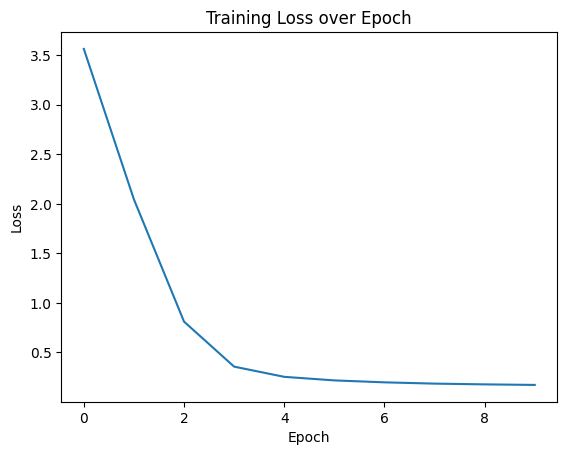

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss over Epoch')
plt.show()

## 결과 확인


In [ ]:
# 파일로 저장했던 네트워크의 가중치들 읽어들이기
model.load_state_dict(torch.load("/content/drive/MyDrive/LLMSearch/Model/Trained_alice/model_010.pth", map_location=device, weights_only=True))
model.eval() # dropout을 사용하지 않음

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(128, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_value): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features

In [ ]:
idx = tokenizer.encode("Project") # 토큰 id의 list
idx = torch.tensor(idx).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(idx)

logits = logits[:, -1, :]

# 가장 확률이 높은 단어 10개 출력
top_logits, top_indices = torch.topk(logits, 10)
for p, i in zip(top_logits.squeeze(0).tolist(), top_indices.squeeze(0).tolist()):
    print(f"{p:.2f}\t {i}\t {tokenizer.decode([i])}")

# 가장 확률이 높은 단어 출력
idx_next = torch.argmax(logits, dim=-1, keepdim=True)
flat = idx_next.squeeze(0) # 배치 차원 제거 torch.Size([1])
out = tokenizer.decode(flat.tolist()) # 텐서를 리스트로 바꿔서 디코드
print(out)

13.77	 20336	  Gutenberg
6.80	 11	 ,
6.07	 1969	  close
5.78	 510	  up
4.89	 1359	 ling
4.61	 82	 s
4.57	 584	  other
4.52	 317	  A
4.49	 503	  out
4.49	 13	 .
 Gutenberg


In [ ]:
def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None, eos_id=None):

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

        if top_k is not None:
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(logits < min_val, torch.tensor(float("-inf")).to(logits.device), logits)

        if temperature > 0.0:
            logits = logits / temperature
            probs = torch.softmax(logits, dim=-1)  # (batch_size, context_len)
            idx_next = torch.multinomial(probs, num_samples=1)  # (batch_size, 1)
        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)  # (batch_size, 1)

        if idx_next == eos_id:
            break

        idx = torch.cat((idx, idx_next), dim=1)  # (batch_size, num_tokens+1)

    return idx

In [ ]:
start_context = input("Start context: ")

# idx = tokenizer.encode(start_context, allowed_special={'<|endoftext|>'})
idx = tokenizer.encode(start_context)
idx = torch.tensor(idx).unsqueeze(0)

context_size = model.pos_emb.weight.shape[0]

for i in range(6):

    token_ids = generate(
        model=model,
        idx=idx.to(device),
        max_new_tokens=50,
        context_size= context_size,
        top_k=50,
        temperature=0.5
    )

    flat = token_ids.squeeze(0) # remove batch dimension
    out = tokenizer.decode(flat.tolist()).replace("\n", " ")

    print(i, ":", out)

Start context: Alice
0 : Alice had been to the seaside once in her life, and had come to the general conclusion, that wherever you go to on the English coast you find a number of bathing machines in the chimney?--"' 'The trial, as we've no
1 : Alice had been to the seaside once in her life, and had come to the general conclusion, that wherever you go to on the English coast you find a number of bathing machines in the goose, the chimney?--and bit afraid of WHAT,
2 : Alice had been to the seaside once in her life, and had come to the general conclusion, that wherever you go to on the English coast you find a number of a number of bathing machines. They were find, going to death."' 'YOU
3 : Alice had been to the seaside once in her life, and had come to the general conclusion, that wherever you go to on the English coast you find a number of bathing machines in the goose, my plan!' 'Oh, as they were saying.'
4 : Alice had been to the seaside once in her life, and had come to the general 